In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
warnings.filterwarnings('ignore')

In [2]:
ae = pd.read_csv("C:\\Users\\Devesh\\Downloads\\NCT00115765 - 1053 (csv)-20240820T215820Z-001\\NCT00115765 - 1053 (csv)\\ae.csv")

In [3]:
ae.shape

(29080, 102)

In [4]:
col_null = ae.isnull().sum()

In [5]:
print(col_null)

STUDYID         0
SITEID          0
SUBJID          0
AGE             0
SEXCD           0
SEX             0
RACCATCD        0
RACCAT          0
TRTDOSE         0
TRTFRQCD        0
TRTFREQ         0
TRTCD           0
TRT             0
ATRTCD          0
ATRT            0
CHEMOCD         0
CHEMO           0
CHEMOICD        0
CHEMOI          0
ACHEMOCD        0
ACHEMO          0
ACHEMMCD        0
ACHEMM          0
FCHEMOCD        9
FCHEMO          9
B_LESNM         0
B_LESNMT        0
B_LESNMN        0
B_METANM        0
B_METACT        0
BMETACTI        0
FSTOXDS      5713
FSTIRDS     23360
DURSURG      2270
PRADJYN         0
PRADJICD        0
PRADJI          0
B_LDHYN       386
B_ECOGCD        0
B_ECOG          0
BECOGICD        0
B_ECOGI         0
DIAGTYCD        0
DIAGTYPE        0
DIAGICD         0
DIAGI           0
RESPSTAT     1635
EVALITT         0
EVALPP          0
PDADEN          0
PDICSIG         0
PDICMIS         0
PDPROMED        0
PDYN            0
KRASCD       1589
KRAS      

In [6]:
result_df = ae.dropna(axis=1)

In [7]:
result_df.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,TRTFREQ,TRTCD,TRT,ATRTCD,ATRT,CHEMOCD,CHEMO,CHEMOICD,CHEMOI,ACHEMOCD,ACHEMO,ACHEMMCD,ACHEMM,B_LESNM,B_LESNMT,B_LESNMN,B_METANM,B_METACT,BMETACTI,PRADJYN,PRADJICD,PRADJI,B_ECOGCD,B_ECOG,BECOGICD,B_ECOGI,DIAGTYCD,DIAGTYPE,DIAGICD,DIAGI,EVALITT,EVALPP,PDADEN,PDICSIG,PDICMIS,PDPROMED,PDYN,EVALKEA,EVALKSA,EVALKUE,TRTDUR,AEANY,AEPAGENO,AELINENO,PHASE,PHASEND,AESTDYI,AETERM,AELLT,AEPT,AEHLT,AEHLGT,AESOC,AECONT,AEPRCNT,AESEV,AEREL,AEINFYN,AEACTCDS,AEACT01,AEACT02,AEACT03,AEACT04,AEACT05,AEACT06,AEACT07,AEACT08,AEACT09,AEACT81,AEACT83,AEACT85,AEACT88,AESER,MEDDRA_V
0,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,Y,1.0,Y,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,N,N,N,N,N,Y,Y,N,685.0,Y,6.0,1.0,Treatment,Treatment,8.0,ACNE RASH,RASH ACNEIFORM,DERMATITIS ACNEIFORM,ACNES,SKIN APPENDAGE CONDITIONS,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,N,N,Mild,Y,N,1,Y,N,N,N,N,N,N,N,N,N,N,N,N,N,8.0
1,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,Y,1.0,Y,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,N,N,N,N,N,Y,Y,N,685.0,Y,6.0,5.0,Treatment,Ongoing,14.0,INCREASED THICK SALIVA,SALIVA INCREASED,SALIVARY HYPERSECRETION,SALIVARY GLAND DISORDERS NEC,SALIVARY GLAND CONDITIONS,GASTROINTESTINAL DISORDERS,Y,N,Mild,Y,N,1,Y,N,N,N,N,N,N,N,N,N,N,N,N,N,8.0
2,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,Y,1.0,Y,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,N,N,N,N,N,Y,Y,N,685.0,Y,6.0,3.0,Treatment,Ongoing,17.0,NAUSEA,NAUSEA,NAUSEA,NAUSEA AND VOMITING SYMPTOMS,GASTROINTESTINAL SIGNS AND SYMPTOMS,GASTROINTESTINAL DISORDERS,Y,N,Mild,N,N,3,N,N,Y,N,N,N,N,N,N,N,N,N,N,N,8.0
3,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,Y,1.0,Y,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,N,N,N,N,N,Y,Y,N,685.0,Y,6.0,2.0,Treatment,Ongoing,28.0,FATIGUE,FATIGUE,FATIGUE,ASTHENIC CONDITIONS,GENERAL SYSTEM DISORDERS NEC,GENERAL DISORDERS AND ADMINISTRATION SITE COND...,Y,N,Moderate,Y,N,1,Y,N,N,N,N,N,N,N,N,N,N,N,N,N,8.0
4,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,Y,1.0,Y,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,N,N,N,N,N,Y,Y,N,685.0,Y,6.0,4.0,Treatment,Ongoing,28.0,LEG CRAMPS,LEG CRAMPS,MUSCLE SPASMS,MUSCLE RELATED SIGNS AND SYMPTOMS NEC,MUSCLE DISORDERS,MUSCULOSKELETAL AND CONNECTIVE TISSUE DISORDERS,Y,N,Mild,N,N,88,N,N,N,N,N,N,N,N,N,N,N,N,Y,N,8.0


In [8]:
result_df.drop(columns=['SEXCD','RACCATCD','AEACTCDS','TRTFREQ','AELLT','AEPT','AEHLT','AETERM' ,'AEHLGT','AECONT','AEPRCNT','AESEV','AESER'],inplace=True)

In [9]:
ae_seg_df =  pd.get_dummies(result_df, drop_first=True, prefix_sep='_')

In [10]:
ae_seg_df.head()

,STUDYID,SITEID,SUBJID,AGE,TRTDOSE,TRTCD,ATRTCD,CHEMOCD,CHEMOICD,ACHEMOCD,ACHEMMCD,B_LESNM,B_LESNMT,B_LESNMN,B_METANM,PRADJICD,B_ECOGCD,BECOGICD,DIAGTYCD,DIAGICD,TRTDUR,AEPAGENO,AELINENO,AESTDYI,MEDDRA_V,SEX_Male,RACCAT_Other,RACCAT_White or Caucasian,TRT_panit. plus bevacizumab with chemotherapy,ATRT_panit. plus bevacizumab with chemotherapy,CHEMO_Oxaliplatin,CHEMOI_Oxaliplatin,ACHEMO_Oxaliplatin,ACHEMM_Oxaliplatin,B_METACT_>1,BMETACTI_>1,PRADJYN_Y,PRADJI_Y,B_ECOG_Symptoms but ambulatory,B_ECOGI_Symptoms but ambulatory,DIAGTYPE_Rectal,DIAGI_Rectal,EVALPP_Y,PDPROMED_Y,PDYN_Y,EVALKEA_Y,EVALKSA_Y,EVALKUE_Y,PHASE_Pre-consent,PHASE_Pre-treatment,PHASE_Short-term/safety follow-up,PHASE_Treatment,PHASEND_Ongoing,PHASEND_Pre-consent,PHASEND_Short-term/safety follow-up,PHASEND_Treatment,AESOC_CARDIAC DISORDERS,"AESOC_CONGENITAL, FAMILIAL AND GENETIC DISORDERS",AESOC_EAR AND LABYRINTH DISORDERS,AESOC_ENDOCRINE DISORDERS,AESOC_EYE DISORDERS,AESOC_GASTROINTESTINAL DISORDERS,AESOC_GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,AESOC_HEPATOBILIARY DISORDERS,AESOC_IMMUNE SYSTEM DISORDERS,AESOC_INFECTIONS AND INFESTATIONS,"AESOC_INJURY, POISONING AND PROCEDURAL COMPLICATIONS",AESOC_INVESTIGATIONS,AESOC_METABOLISM AND NUTRITION DISORDERS,AESOC_MUSCULOSKELETAL AND CONNECTIVE TISSUE DISORDERS,"AESOC_NEOPLASMS BENIGN, MALIGNANT AND UNSPECIFIED (INCL CYSTS AND POLYPS)",AESOC_NERVOUS SYSTEM DISORDERS,AESOC_PSYCHIATRIC DISORDERS,AESOC_RENAL AND URINARY DISORDERS,AESOC_REPRODUCTIVE SYSTEM AND BREAST DISORDERS,"AESOC_RESPIRATORY, THORACIC AND MEDIASTINAL DISORDERS",AESOC_SKIN AND SUBCUTANEOUS TISSUE DISORDERS,AESOC_SOCIAL CIRCUMSTANCES,AESOC_SURGICAL AND MEDICAL PROCEDURES,AESOC_VASCULAR DISORDERS,AEREL_Y,AEINFYN_Y,AEACT01_Y,AEACT02_Y,AEACT03_Y,AEACT04_Y,AEACT06_Y,AEACT07_Y,AEACT08_Y,AEACT09_Y,AEACT81_Y,AEACT83_Y,AEACT85_Y,AEACT88_Y
0,20040249,101,249101001,67.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,100.0,1.0,99.0,1.0,1.0,0.0,0.0,1251.0,1251.0,685.0,6.0,1.0,8.0,8.0,0,0,0,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0
1,20040249,101,249101001,67.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,100.0,1.0,99.0,1.0,1.0,0.0,0.0,1251.0,1251.0,685.0,6.0,5.0,14.0,8.0,0,0,0,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0
2,20040249,101,249101001,67.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,100.0,1.0,99.0,1.0,1.0,0.0,0.0,1251.0,1251.0,685.0,6.0,3.0,17.0,8.0,0,0,0,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,20040249,101,249101001,67.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,100.0,1.0,99.0,1.0,1.0,0.0,0.0,1251.0,1251.0,685.0,6.0,2.0,28.0,8.0,0,0,0,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0
4,20040249,101,249101001,67.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,100.0,1.0,99.0,1.0,1.0,0.0,0.0,1251.0,1251.0,685.0,6.0,4.0,28.0,8.0,0,0,0,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [11]:
ae_seg_df.shape

(29080, 94)

In [12]:
aesoc_cols = [col for col in ae_seg_df.columns if col.startswith('AESOC_')]

In [13]:
grouped = ae_seg_df.groupby('SUBJID')

In [14]:
aesoc_counts = grouped[aesoc_cols].sum().reset_index()

In [15]:
columns_to_convert = [col for col in aesoc_counts.columns if col != 'SUBJID']
aesoc_counts[columns_to_convert] = (aesoc_counts[columns_to_convert] > 0).astype(int)

In [16]:
aesoc_counts

,SUBJID,AESOC_CARDIAC DISORDERS,"AESOC_CONGENITAL, FAMILIAL AND GENETIC DISORDERS",AESOC_EAR AND LABYRINTH DISORDERS,AESOC_ENDOCRINE DISORDERS,AESOC_EYE DISORDERS,AESOC_GASTROINTESTINAL DISORDERS,AESOC_GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,AESOC_HEPATOBILIARY DISORDERS,AESOC_IMMUNE SYSTEM DISORDERS,AESOC_INFECTIONS AND INFESTATIONS,"AESOC_INJURY, POISONING AND PROCEDURAL COMPLICATIONS",AESOC_INVESTIGATIONS,AESOC_METABOLISM AND NUTRITION DISORDERS,AESOC_MUSCULOSKELETAL AND CONNECTIVE TISSUE DISORDERS,"AESOC_NEOPLASMS BENIGN, MALIGNANT AND UNSPECIFIED (INCL CYSTS AND POLYPS)",AESOC_NERVOUS SYSTEM DISORDERS,AESOC_PSYCHIATRIC DISORDERS,AESOC_RENAL AND URINARY DISORDERS,AESOC_REPRODUCTIVE SYSTEM AND BREAST DISORDERS,"AESOC_RESPIRATORY, THORACIC AND MEDIASTINAL DISORDERS",AESOC_SKIN AND SUBCUTANEOUS TISSUE DISORDERS,AESOC_SOCIAL CIRCUMSTANCES,AESOC_SURGICAL AND MEDICAL PROCEDURES,AESOC_VASCULAR DISORDERS
0,249101001,0,0,0,0,0,1,1,0,0,1,0,0,1,1,0,1,0,0,1,1,1,0,0,0
1,249101002,0,0,0,0,0,1,1,0,0,1,0,1,1,0,0,1,0,0,0,0,1,0,0,0
2,249101003,1,0,0,0,0,1,1,0,0,1,1,0,1,1,0,1,1,0,0,1,1,0,0,1
3,249101005,1,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0
4,249101006,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,1,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
816,249292023,0,0,0,0,0,1,1,0,0,1,1,1,1,1,0,1,1,0,0,1,1,0,0,0
817,249294003,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,1,0,1,0,1,1,0,0,0
818,249294006,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,1,0
819,249294007,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


In [17]:
# For each non-AESOC column, drop it if it varies within the same SUBJID group
def drop_inconsistent_columns(group):
    # Keeping only columns that are consistent across all rows in each group
    consistent_columns = [col for col in group.columns if group[col].nunique() == 1]
    return group[consistent_columns].head(1)  # Retain only one row per group

In [18]:
consistent_features = grouped.apply(drop_inconsistent_columns).reset_index(drop=True)
consistent_features.drop(columns=aesoc_cols ,inplace=True)
result = pd.merge(consistent_features, aesoc_counts, on='SUBJID', how='left')

In [19]:
result.fillna(0, inplace=True)

In [20]:
result.head(10)

,STUDYID,SITEID,SUBJID,AGE,TRTDOSE,TRTCD,ATRTCD,CHEMOCD,CHEMOICD,ACHEMOCD,ACHEMMCD,B_LESNM,B_LESNMT,B_LESNMN,B_METANM,PRADJICD,B_ECOGCD,BECOGICD,DIAGTYCD,DIAGICD,TRTDUR,MEDDRA_V,SEX_Male,RACCAT_Other,RACCAT_White or Caucasian,TRT_panit. plus bevacizumab with chemotherapy,ATRT_panit. plus bevacizumab with chemotherapy,CHEMO_Oxaliplatin,CHEMOI_Oxaliplatin,ACHEMO_Oxaliplatin,ACHEMM_Oxaliplatin,B_METACT_>1,BMETACTI_>1,PRADJYN_Y,PRADJI_Y,B_ECOG_Symptoms but ambulatory,B_ECOGI_Symptoms but ambulatory,DIAGTYPE_Rectal,DIAGI_Rectal,EVALPP_Y,PDPROMED_Y,PDYN_Y,EVALKEA_Y,EVALKSA_Y,EVALKUE_Y,PHASE_Pre-consent,PHASE_Pre-treatment,PHASE_Short-term/safety follow-up,PHASE_Treatment,PHASEND_Pre-consent,PHASEND_Short-term/safety follow-up,AEINFYN_Y,AEACT06_Y,AEACT07_Y,AEACT09_Y,AEACT83_Y,AEACT85_Y,AEREL_Y,AEACT02_Y,AEACT04_Y,AEACT08_Y,AEACT81_Y,AEACT88_Y,AEPAGENO,PHASEND_Ongoing,PHASEND_Treatment,AEACT01_Y,AEACT03_Y,AESTDYI,AELINENO,AESOC_CARDIAC DISORDERS,"AESOC_CONGENITAL, FAMILIAL AND GENETIC DISORDERS",AESOC_EAR AND LABYRINTH DISORDERS,AESOC_ENDOCRINE DISORDERS,AESOC_EYE DISORDERS,AESOC_GASTROINTESTINAL DISORDERS,AESOC_GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,AESOC_HEPATOBILIARY DISORDERS,AESOC_IMMUNE SYSTEM DISORDERS,AESOC_INFECTIONS AND INFESTATIONS,"AESOC_INJURY, POISONING AND PROCEDURAL COMPLICATIONS",AESOC_INVESTIGATIONS,AESOC_METABOLISM AND NUTRITION DISORDERS,AESOC_MUSCULOSKELETAL AND CONNECTIVE TISSUE DISORDERS,"AESOC_NEOPLASMS BENIGN, MALIGNANT AND UNSPECIFIED (INCL CYSTS AND POLYPS)",AESOC_NERVOUS SYSTEM DISORDERS,AESOC_PSYCHIATRIC DISORDERS,AESOC_RENAL AND URINARY DISORDERS,AESOC_REPRODUCTIVE SYSTEM AND BREAST DISORDERS,"AESOC_RESPIRATORY, THORACIC AND MEDIASTINAL DISORDERS",AESOC_SKIN AND SUBCUTANEOUS TISSUE DISORDERS,AESOC_SOCIAL CIRCUMSTANCES,AESOC_SURGICAL AND MEDICAL PROCEDURES,AESOC_VASCULAR DISORDERS
0,20040249,101,249101001,67.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,100.0,1.0,99.0,1.0,1.0,0.0,0.0,1251.0,1251.0,685.0,8.0,0,0,0,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,1,0,0,1,0,0,1,1,0,1,0,0,1,1,1,0,0,0
1,20040249,101,249101002,72.0,0.0,12.0,12.0,78.0,78.0,78.0,78.0,101.0,2.0,99.0,2.0,0.0,1.0,1.0,1251.0,1251.0,365.0,8.0,1,0,1,0,0,1,1,1,1,1,1,0,0,1,1,0,0,1,0,0,1,1,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,1,0,0,1,0,1,1,0,0,1,0,0,0,0,1,0,0,0
2,20040249,101,249101003,78.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,101.0,2.0,99.0,2.0,0.0,0.0,0.0,1251.0,1251.0,166.0,8.0,1,0,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,1,1,0,0,1,1,0,1,1,0,1,1,0,0,1,1,0,0,1
3,20040249,101,249101005,66.0,0.0,12.0,12.0,78.0,78.0,78.0,78.0,101.0,2.0,99.0,2.0,0.0,1.0,1.0,1251.0,1251.0,85.0,8.0,0,0,0,0,0,1,1,1,1,1,1,0,0,1,1,0,0,1,0,0,1,1,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0
4,20040249,101,249101006,67.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,2.0,1.0,1.0,1.0,1.0,0.0,0.0,1252.0,1252.0,302.0,8.0,1,0,1,1,1,1,1,1,1,0,0,1,1,0,0,1,1,1,0,0,0,0,1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,1,0,1,1,0,0,0
5,20040249,101,249101007,70.0,0.0,12.0,12.0,78.0,78.0,78.0,78.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1251.0,1251.0,512.0,8.0,1,0,1,0,0,1,1,1,1,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0,0,0,1,1,1,0,0,1,0,0,0,1,0,1,1,0,0,1,1,0,0,0
6,20040249,101,249101008,70.0,6.0,11.0,11.0,78.0,78.0,78.0,78.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1252.0,1252.0,316.0,8.0,1,0,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,0,0,1,1,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0,0,0,1,1,1,0,0,1,

In [21]:
result.shape

(821, 94)

In [22]:
result.to_csv('processed_dataframe_segAE_1053.csv', index=False)

In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import mean_squared_error
from scipy.stats import uniform, randint

# For reproducibility
import numpy as np
np.random.seed(42)



In [24]:
X = result.drop(columns=aesoc_cols)
y = result[aesoc_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [26]:
xgb_param_grid = {
    'n_estimators': randint(50, 500),
    'max_depth': randint(3, 10),
    'learning_rate': uniform(0.01, 0.1),
    'subsample': uniform(0.6, 0.9),
    'colsample_bytree': uniform(0.6, 0.9)
}

In [56]:
param_grid={
    'n_estimators': randint(50, 500),
    'max_depth': randint(3, 10),
    'learning_rate': uniform(0.01, 0.1),
    'subsample': uniform(0.6, 0.9),
    'colsample_bytree': uniform(0.6, 0.9)
}

In [52]:
param_grid = {
    'estimator__n_estimators': randint(50, 500),
    'estimator__max_depth': randint(3, 10),
    'estimator__learning_rate': uniform(0.01, 0.1),
    'estimator__subsample': uniform(0.6, 0.9),
    'estimator__colsample_bytree': uniform(0.6, 0.9),
}

In [27]:
# Random Forest parameter distribution
rf_param_dist = {
    'estimator__n_estimators': randint(100, 500),  
    'estimator__max_depth': randint(10, 50),  
    'estimator__min_samples_split': randint(2, 20), 
    'estimator__min_samples_leaf': randint(1, 10),  
    'estimator__bootstrap': [True, False]  
}

XGB Classifier

In [29]:
base_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
multi_output_model = MultiOutputClassifier(base_model)

In [31]:
random_search = RandomizedSearchCV(
    estimator=multi_output_model,
    param_distributions=param_grid,
    n_iter=50, 
    cv=3,       
    verbose=2,
    random_state=42,
    n_jobs=-1   
)

In [32]:
random_search.fit(X_train, y_train)
print("Best parameters:", random_search.best_params_)
best_model = random_search.best_estimator_

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best parameters: {'estimator__subsample': 1.0, 'estimator__n_estimators': 300, 'estimator__min_child_weight': 3, 'estimator__max_depth': 4, 'estimator__learning_rate': 0.01, 'estimator__colsample_bytree': 0.6}


In [33]:
y_pred = best_model.predict(X_test)

In [34]:
for i, col in enumerate(y.columns):
    print(f"\nClassification Report for {col}:")
    print(classification_report(y_test.iloc[:, i], y_pred[:, i]))
    print(f"Accuracy for {col}: {accuracy_score(y_test.iloc[:, i], y_pred[:, i])}")


Classification Report for AESOC_CARDIAC DISORDERS:
              precision    recall  f1-score   support

           0       0.87      1.00      0.93       144
           1       0.00      0.00      0.00        21

    accuracy                           0.87       165
   macro avg       0.44      0.50      0.47       165
weighted avg       0.76      0.87      0.81       165

Accuracy for AESOC_CARDIAC DISORDERS: 0.8727272727272727

Classification Report for AESOC_CONGENITAL, FAMILIAL AND GENETIC DISORDERS:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       165

    accuracy                           1.00       165
   macro avg       1.00      1.00      1.00       165
weighted avg       1.00      1.00      1.00       165

Accuracy for AESOC_CONGENITAL, FAMILIAL AND GENETIC DISORDERS: 1.0

Classification Report for AESOC_EAR AND LABYRINTH DISORDERS:
              precision    recall  f1-score   support

           0       0.93      1

In [36]:
feature_importances = []
for i, estimator in enumerate(best_model.estimators_):
    importance = estimator.feature_importances_
    feature_importances.append(pd.DataFrame({
        'feature': X.columns,
        'importance': importance,
        'target': y.columns[i]
    }))

# Combining feature importances for all target variables
feature_importance_combined = pd.concat(feature_importances, ignore_index=True)

# Calculating average importance across all targets
avg_importance = feature_importance_combined.groupby('feature')['importance'].mean().reset_index()
avg_importance = avg_importance.sort_values('importance', ascending=False)

print("Average feature importance across all target variables:")
print(avg_importance)

Average feature importance across all target variables:
                                           feature  importance
68                                          TRTDUR    0.059032
30                                        B_LESNMN    0.049211
18                                        AEPAGENO    0.042662
21                                             AGE    0.035267
22                                          ATRTCD    0.032727
29                                         B_LESNM    0.032049
63                                          SITEID    0.031015
65                                          SUBJID    0.029495
66                                           TRTCD    0.029325
67                                         TRTDOSE    0.028237
62                                        SEX_Male    0.028030
23  ATRT_panit. plus bevacizumab with chemotherapy    0.027329
69   TRT_panit. plus bevacizumab with chemotherapy    0.026407
31                                        B_LESNMT    0.025241

In [37]:
# individul feature importance for each target variable separately
for target in y.columns:
    print(f"\nTop feature importance for {target}:")
    target_importance = feature_importance_combined[feature_importance_combined['target'] == target]
    target_importance = target_importance.sort_values('importance', ascending=False)
    print(target_importance.head(10)) 



Top feature importance for AESOC_CARDIAC DISORDERS:
                      feature  importance                   target
8                    CHEMOICD    0.062802  AESOC_CARDIAC DISORDERS
20                     TRTDUR    0.056542  AESOC_CARDIAC DISORDERS
19                    DIAGICD    0.050895  AESOC_CARDIAC DISORDERS
32                BMETACTI_>1    0.048960  AESOC_CARDIAC DISORDERS
37            DIAGTYPE_Rectal    0.041126  AESOC_CARDIAC DISORDERS
11                    B_LESNM    0.039704  AESOC_CARDIAC DISORDERS
2                      SUBJID    0.034770  AESOC_CARDIAC DISORDERS
22                   SEX_Male    0.034314  AESOC_CARDIAC DISORDERS
24  RACCAT_White or Caucasian    0.032865  AESOC_CARDIAC DISORDERS
23               RACCAT_Other    0.030580  AESOC_CARDIAC DISORDERS

Top feature importance for AESOC_CONGENITAL, FAMILIAL AND GENETIC DISORDERS:
                                 feature  importance                                            target
83                           

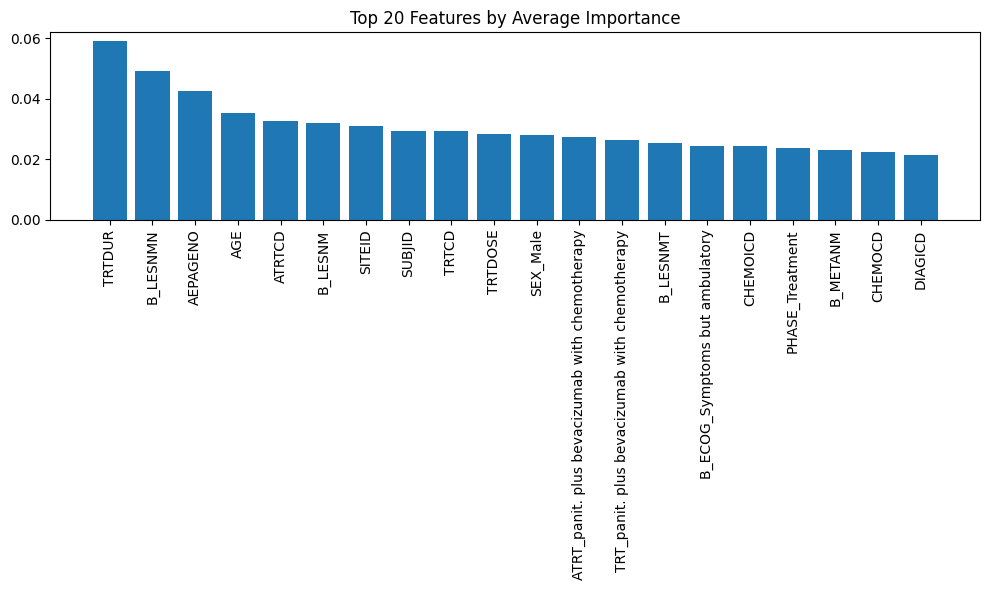

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(avg_importance['feature'][:20], avg_importance['importance'][:20])
plt.xticks(rotation=90)
plt.title('Top 20 Features by Average Importance')
plt.tight_layout()
plt.show()

# managing data imbalance